In [0]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2

In [0]:
from fastai.tabular import *
from sklearn.utils import shuffle
import pandas as pd

In [0]:
!wget --header="Host: doc-04-9c-docs.googleusercontent.com" --header="User-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/75.0.3770.100 Safari/537.36" --header="Accept: text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,image/apng,*/*;q=0.8,application/signed-exchange;v=b3" --header="Accept-Language: en-US,en;q=0.9" --header="Referer: https://drive.google.com/drive/u/0/my-drive" --header="Cookie: AUTH_4lgch8kproorp87c5erpsi9rqpbk46dg_nonce=srccra433pdq4" --header="Connection: keep-alive" "https://doc-04-9c-docs.googleusercontent.com/docs/securesc/0ga3her86at4fpdr2b9n3spfq1b4g359/c5t02ufl1u3amitg0lu2tbb6pkcikmbq/1561622400000/14696292948499217652/14696292948499217652/1bRqhEEUpVxZd_dtfoWWGq22z-lZHDJYb?e=download&h=06864318269717761326&nonce=srccra433pdq4&user=14696292948499217652&hash=rq72elm82l8o31bbopqml6m5rgq1f9kp" -O "train_coco.csv" -c

--2019-06-27 08:38:41--  https://doc-04-9c-docs.googleusercontent.com/docs/securesc/0ga3her86at4fpdr2b9n3spfq1b4g359/c5t02ufl1u3amitg0lu2tbb6pkcikmbq/1561622400000/14696292948499217652/14696292948499217652/1bRqhEEUpVxZd_dtfoWWGq22z-lZHDJYb?e=download&h=06864318269717761326&nonce=srccra433pdq4&user=14696292948499217652&hash=rq72elm82l8o31bbopqml6m5rgq1f9kp
Resolving doc-04-9c-docs.googleusercontent.com (doc-04-9c-docs.googleusercontent.com)... 108.177.97.132, 2404:6800:4008:c00::84
Connecting to doc-04-9c-docs.googleusercontent.com (doc-04-9c-docs.googleusercontent.com)|108.177.97.132|:443... connected.
HTTP request sent, awaiting response... 416 Requested range not satisfiable

    The file is already fully retrieved; nothing to do.



In [0]:
chunksize = 10 ** 6
for chunk in pd.read_csv('train_coco.csv', chunksize=chunksize):
    print(chunk.head())



# df = pd.read_csv('train_coco.csv')
# print(df.head())

   Unnamed: 0        image_name  0-0.1  ...  0.8-0.9  0.9-1.0  target
0           0  000000022953.txt      5  ...        3        1       1
1           1  000000022953.txt     37  ...        2        0       1
2           2  000000022953.txt      6  ...        4        0       1
3           3  000000022953.txt      7  ...        1        0       1
4           4  000000022953.txt      1  ...        1        0       0

[5 rows x 13 columns]
         Unnamed: 0        image_name  0-0.1  ...  0.8-0.9  0.9-1.0  target
1000000        2686  000000538737.txt      2  ...        0        0       0
1000001        2687  000000538737.txt      3  ...        0        0       0
1000002        2688  000000538737.txt      2  ...        0        0       0
1000003        2689  000000538737.txt      1  ...        0        0       0
1000004        2690  000000538737.txt      1  ...        0        0       0

[5 rows x 13 columns]
         Unnamed: 0        image_name  0-0.1  ...  0.8-0.9  0.9-1.0  target
20

KeyboardInterrupt: ignored

In [0]:
dep_var = 'target'
cont_names = ['0-0.1', '0.1-0.2', '0.2-0.3', '0.3-0.4', '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7-0.8', '0.8-0.9', '0.9-1.0']
procs = [Normalize]

In [0]:
test = TabularList.from_df(df.iloc[42942:47942].copy(), cont_names=cont_names)

In [0]:
data = (TabularList.from_df(df, cont_names=cont_names, procs=procs)
                           .split_by_idx(list(range(42942,47942)))
                           .label_from_df(cols=dep_var)
                           .add_test(test)
                           .databunch())

In [0]:
data.show_batch(rows=10)

0-0.1,0.1-0.2,0.2-0.3,0.3-0.4,0.4-0.5,0.5-0.6,0.6-0.7,0.7-0.8,0.8-0.9,0.9-1.0,target
-0.2394,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.5012,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.5012,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.5012,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
0.0223,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.2394,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.5012,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.5012,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.2394,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0
-0.5012,-0.2465,-0.1949,-0.1716,-0.1580,-0.1484,-0.1395,-0.1358,-0.1264,-0.1027,0


In [0]:
learn = tabular_learner(data, layers=[200,100], metrics=accuracy)

In [0]:
learn.model

TabularModel(
  (embeds): ModuleList()
  (emb_drop): Dropout(p=0.0)
  (bn_cont): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (layers): Sequential(
    (0): Linear(in_features=10, out_features=200, bias=True)
    (1): ReLU(inplace)
    (2): BatchNorm1d(200, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=200, out_features=100, bias=True)
    (4): ReLU(inplace)
    (5): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Linear(in_features=100, out_features=2, bias=True)
  )
)

In [0]:
learn.lr_find()

LR Finder is complete, type {learner_name}.recorder.plot() to see the graph.


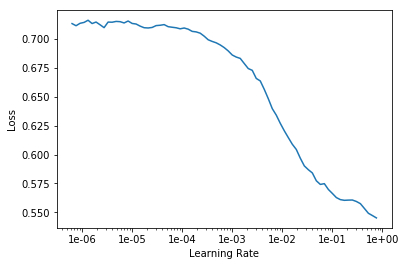

In [0]:
learn.recorder.plot()

In [0]:
lr = 1e-01

In [0]:
learn.fit(1, lr)

epoch,train_loss,valid_loss,accuracy,time
0,0.428162,0.523709,0.833000,00:04


In [0]:
learn.fit(5, lr, cycle_len=1)

TypeError: ignored